
# Decision Tree Classification: Bank Marketing

Project Overview

The objective of this project is to build a Decision Tree Classification model that predicts whether a customer will subscribe to a bank term deposit.

Machine Learning Workflow

1. Data Loading and Understanding
2. Data Cleaning
3. Exploratory Data Analysis (EDA)
4. Feature Engineering
5. Data Preprocessing
6. Model Training
7. Hyperparameter Tuning
8. Model Evaluation
9. Decision Tree Visualization
10. Conclusions and Insights

Problem Type: Supervised Machine Learning — Binary Classification

Dataset: UCI Bank Marketing Dataset

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier

In /Users/alfaizkhan/Documents/Machine learning/MLE/lib/python3.13/site-packages/matplotlib/mpl-data/stylelib/_classic_test_patch 2.mplstyle: The text.kerning_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
In /Users/alfaizkhan/Documents/Machine learning/MLE/lib/python3.13/site-packages/matplotlib/mpl-data/stylelib/classic 2.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.
In /Users/alfaizkhan/Documents/Machine learning/MLE/lib/python3.13/site-packages/matplotlib/mpl-data/stylelib/bmh 2.mplstyle: The text.hinting_factor rcParam was deprecated in Matplotlib 3.11 and will be removed in 3.13.


In [11]:
DATA_PATH = Path("../data/bank-full.csv")
df = pd.read_csv(DATA_PATH,sep=';')
print(df.shape)

(45211, 17)


In [47]:
print(df.sample(5))

       age          job  marital  education default  balance housing loan  \
4352    25  blue-collar  married  secondary      no      316     yes  yes   
19113   48     services  married  secondary      no     1573      no   no   
28060   34     services   single   tertiary      no      239      no   no   
17401   31     services   single  secondary      no      456     yes   no   
27030   30   technician  married  secondary      no      239     yes   no   

        contact  day month  duration  campaign  pdays  previous poutcome   y  
4352    unknown   19   may       360         2     -1         0  unknown  no  
19113  cellular    5   aug       165         1     -1         0  unknown  no  
28060  cellular   28   jan       699         2     -1         0  unknown  no  
17401  cellular   28   jul       322        11     -1         0  unknown  no  
27030  cellular   21   nov       302         2     95         8  failure  no  


In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [50]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


In [54]:
print("Target variable counts:")
print(df["y"].value_counts())

print("\nTarget variable percentages:")
print(df["y"].value_counts(normalize=True).mul(100).round(2))

Target variable counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Target variable percentages:
y
no     88.3
yes    11.7
Name: proportion, dtype: float64


In [57]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [58]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [60]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts().head(5))


job:
job
blue-collar    9732
management     9458
technician     7597
admin.         5171
services       4154
Name: count, dtype: int64

marital:
marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64

education:
education
secondary    23202
tertiary     13301
primary       6851
unknown       1857
Name: count, dtype: int64

default:
default
no     44396
yes      815
Name: count, dtype: int64

housing:
housing
yes    25130
no     20081
Name: count, dtype: int64

loan:
loan
no     37967
yes     7244
Name: count, dtype: int64

contact:
contact
cellular     29285
unknown      13020
telephone     2906
Name: count, dtype: int64

month:
month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
Name: count, dtype: int64

poutcome:
poutcome
unknown    36959
failure     4901
other       1840
success     1511
Name: count, dtype: int64

y:
y
no     39922
yes     5289
Name: count, dtype: int64


In [63]:

numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']


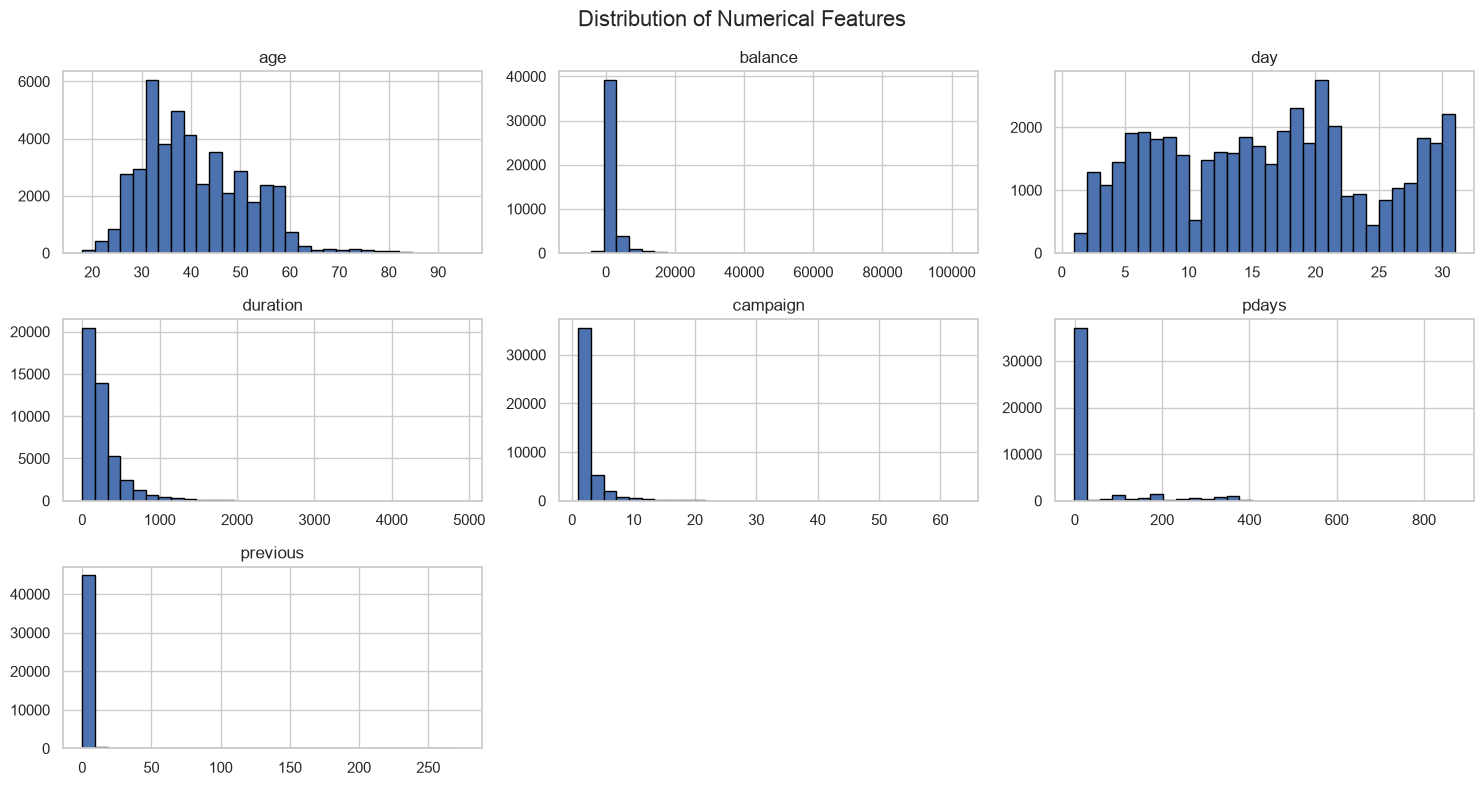

In [67]:
df[numerical_features].hist(
    figsize=(15, 8),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

In [68]:
df[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


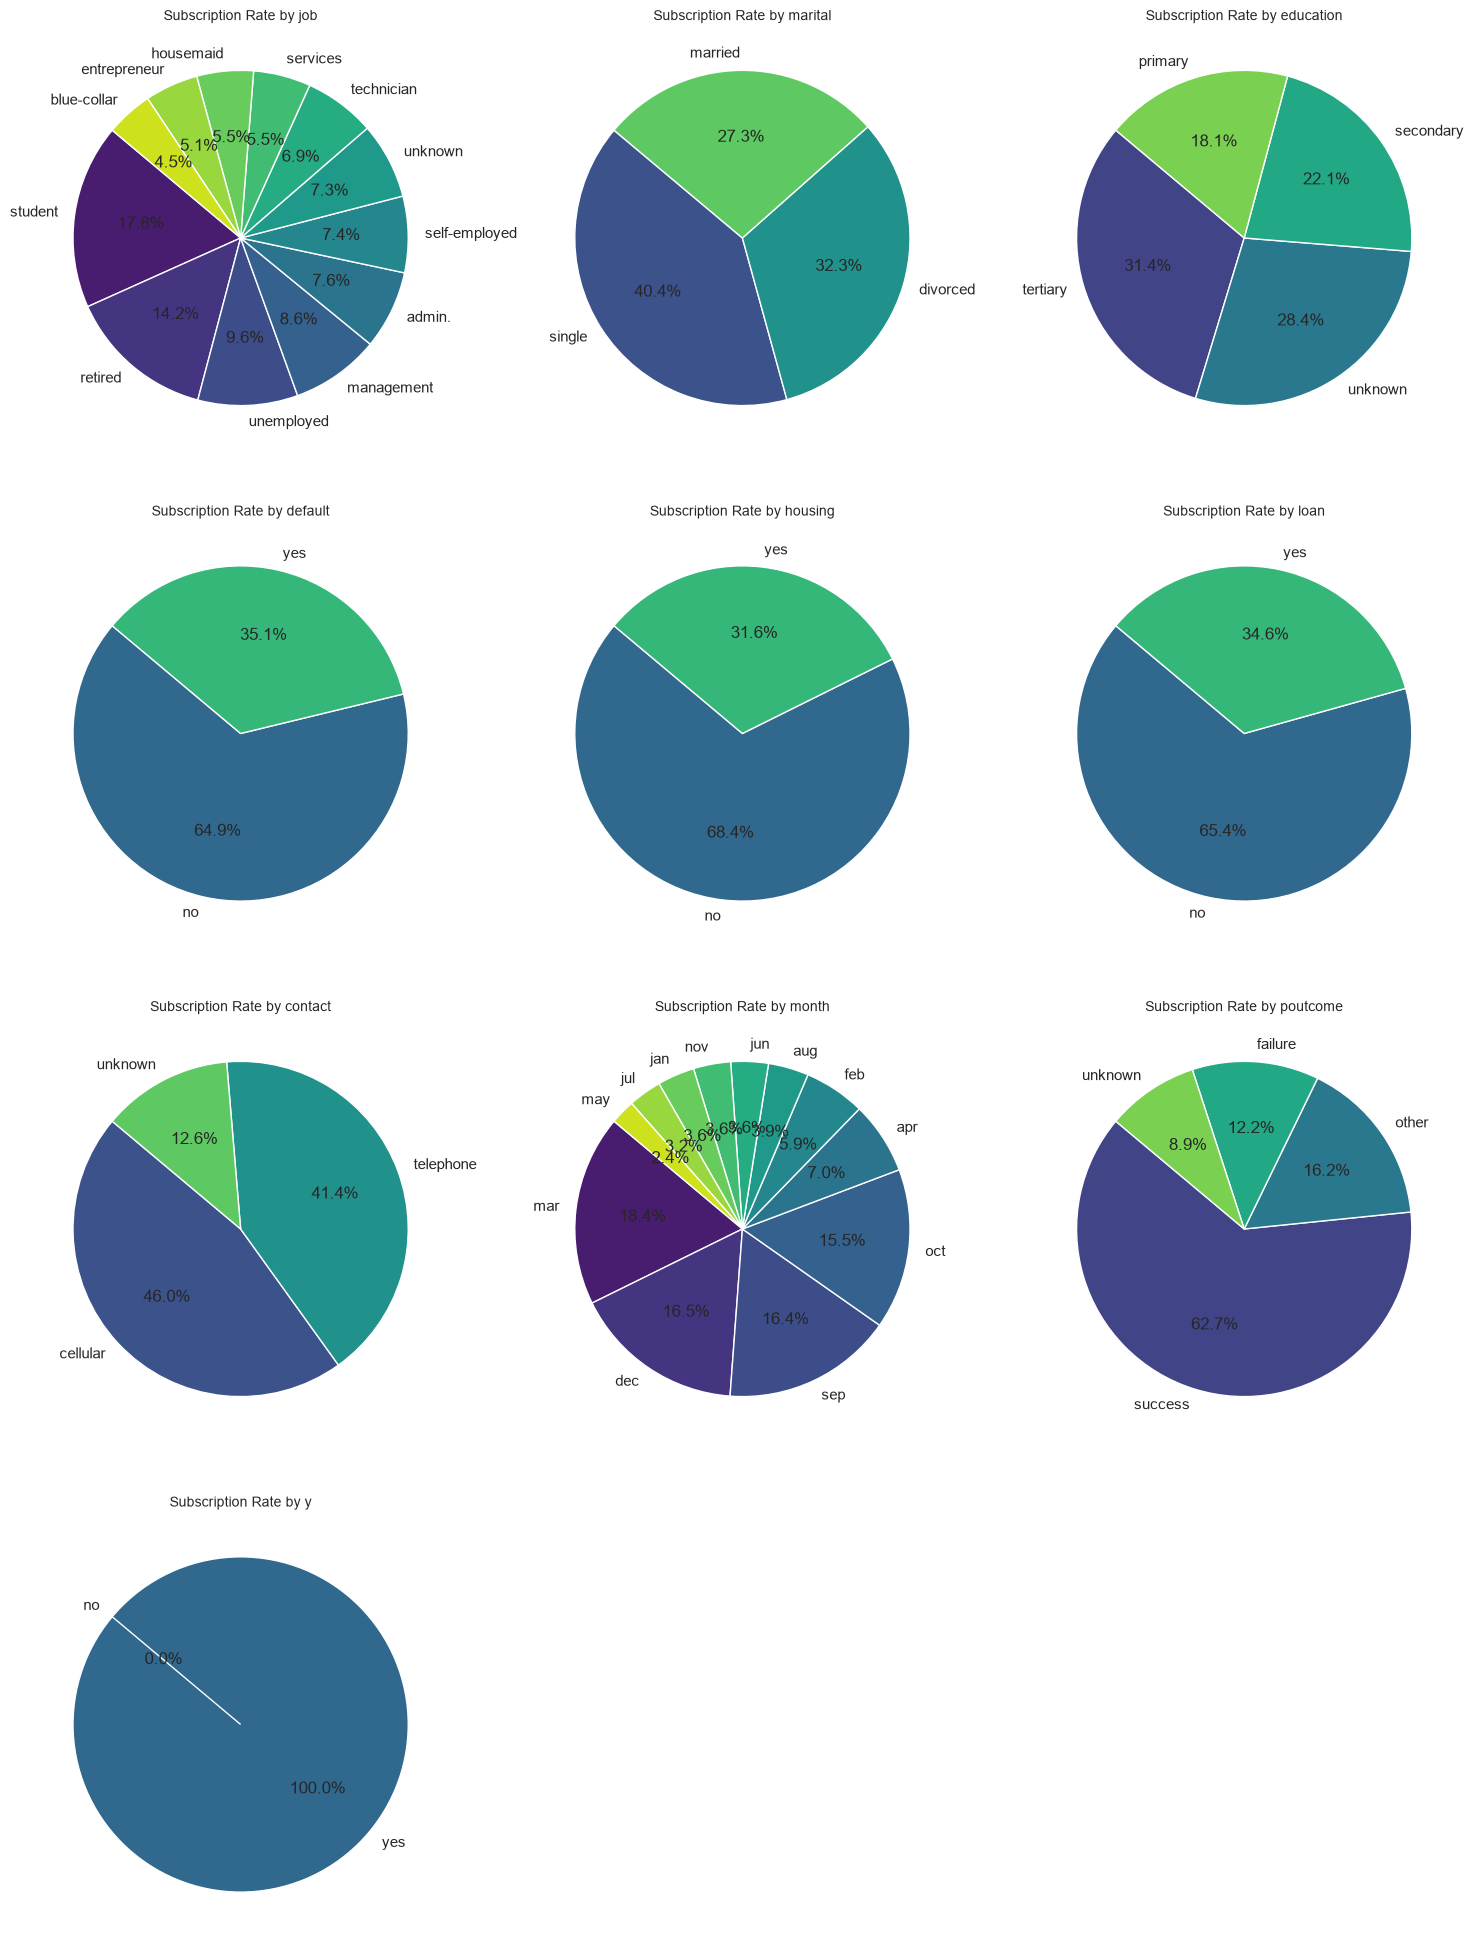

In [107]:
import math
import matplotlib.pyplot as plt
import seaborn as sns


n_cols = 3  
n_rows = math.ceil(len(categorical_features) / n_cols)

# 2. Initialize the subplot matrix grid layout
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))

# Flatten the axes array to easily iterate over it in a 1D loop
if len(categorical_features) > 1:
    axes = axes.flatten()
else:
    axes = [axes]

# 3. Loop and plot each feature on its own grid axis
for i, col in enumerate(categorical_features):
    rates = (
        df.groupby(col, observed=True)["y"]
        .apply(lambda x: (x == "yes").mean() * 100)
        .sort_values(ascending=False)
    )
    
    labels = rates.index
    values = rates.values
    ax = axes[i]
    
    # Plot directly on the specific matrix slot
    ax.pie(
        values, 
        labels=labels, 
        autopct='%1.1f%%', 
        colors=sns.color_palette('viridis', len(labels)),
        startangle=140
    )
    ax.set_title(f"Subscription Rate by {col}", fontsize=10)

# 4. Remove empty slots if your total features don't fill the last row completely
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

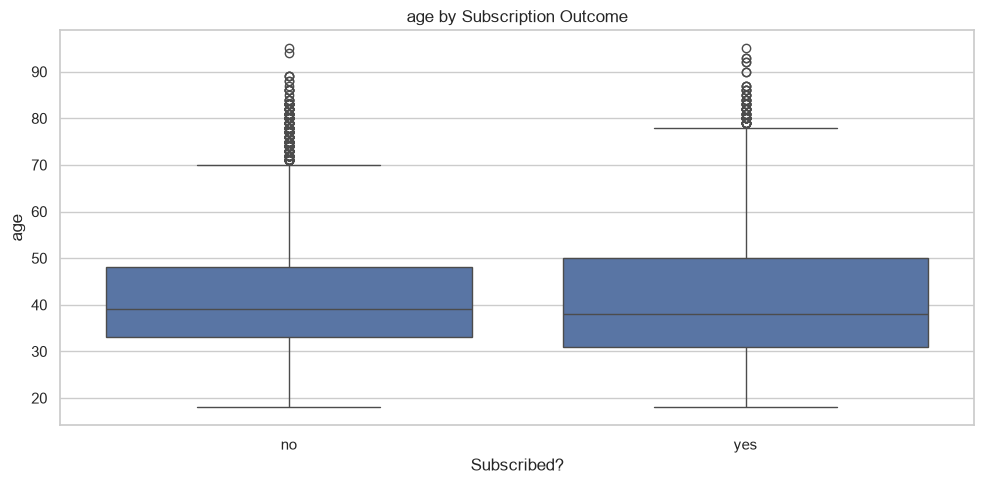

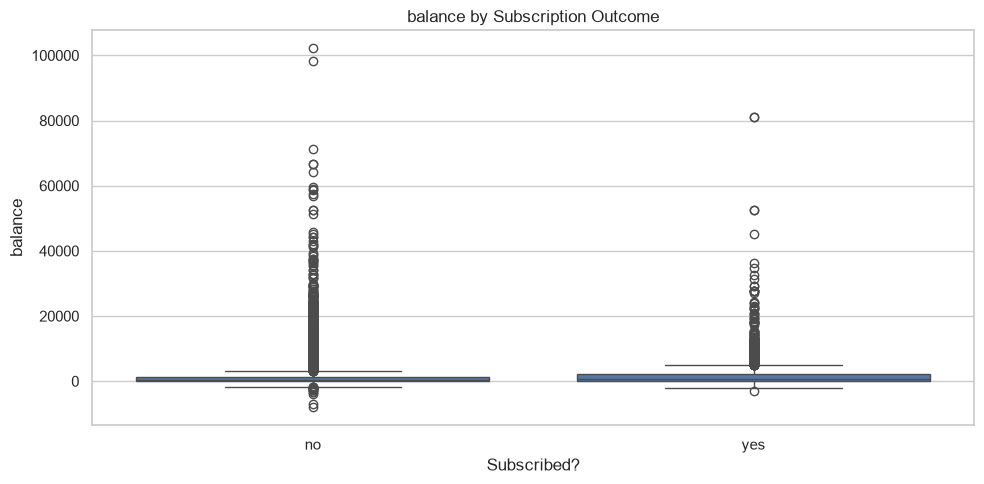

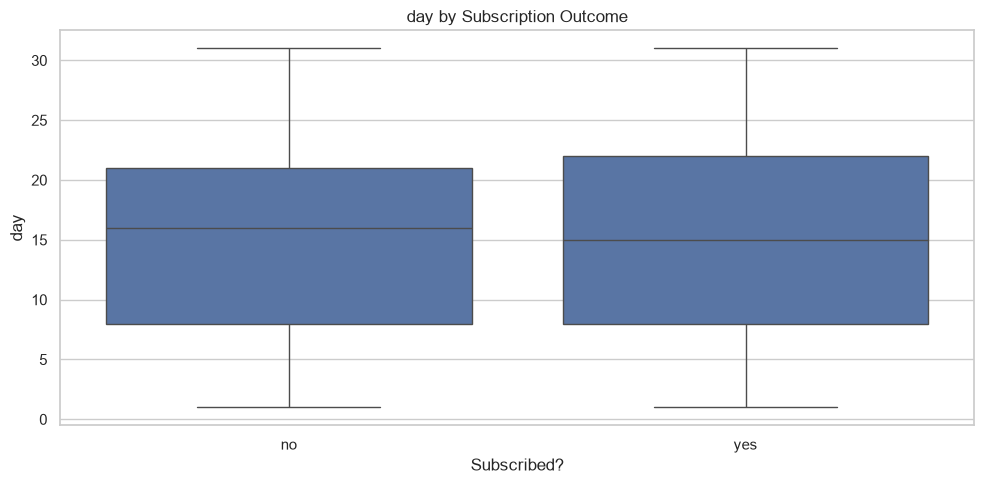

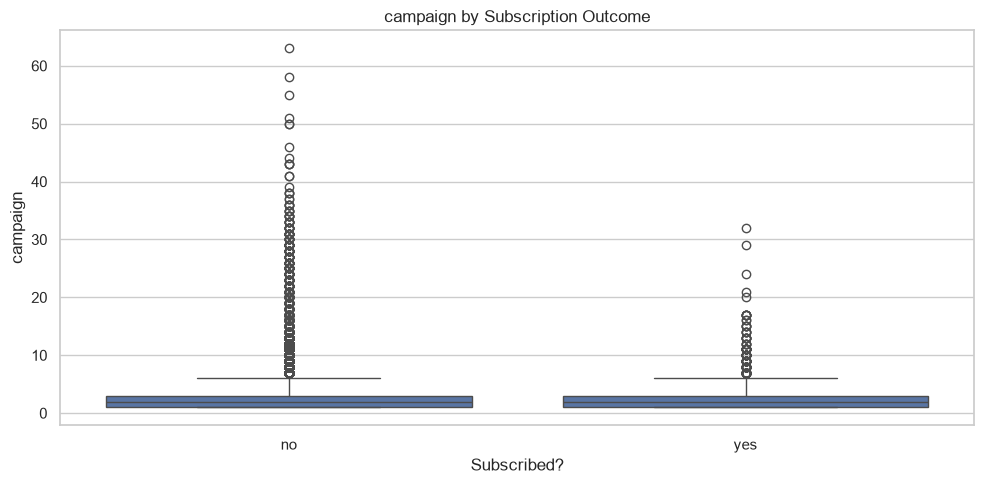

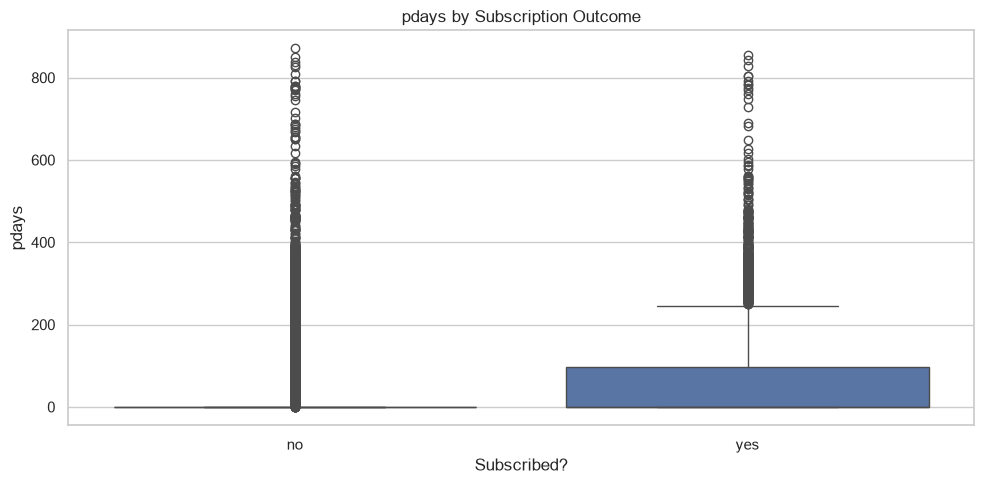

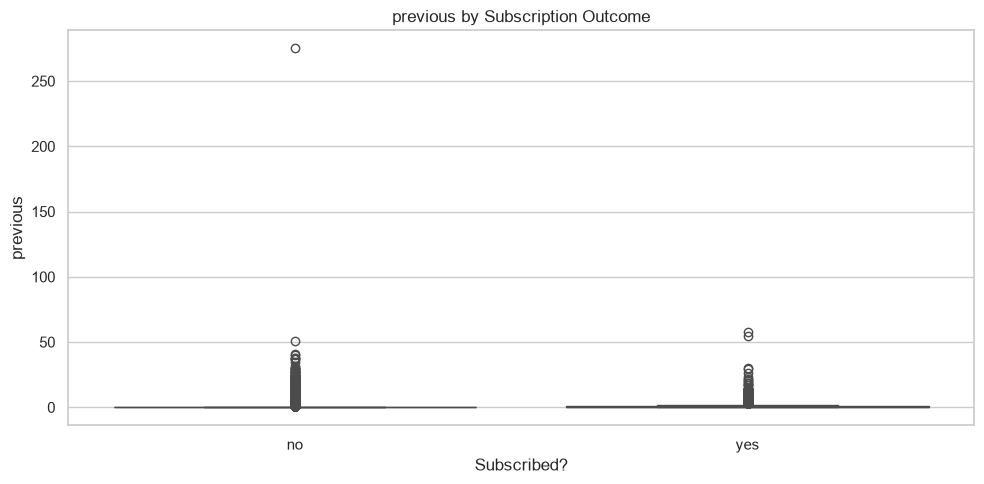

In [103]:
numerical_features = df.select_dtypes(
    include=["number"]
).columns.drop("duration").tolist()

for col in numerical_features:
    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=df,
        x="y",
        y=col
    )

    plt.title(f"{col} by Subscription Outcome")
    plt.xlabel("Subscribed?")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

## Feature Engineering

In this stage, we prepare the dataset for Decision Tree Classification.

Our target variable is `y`:
- `yes` = 1 (customer subscribed)
- `no` = 0 (customer did not subscribe)

We will exclude `duration` because it is not available before a marketing call.

In [117]:
# Create a copy of the original dataset
df_model = df.copy()

# Convert target labels into binary values
df_model["y"] = df_model["y"].map({
    "no": 0,
    "yes": 1
})

# Separate features and target
X = df_model.drop(columns=["y", "duration"])
y = df_model["y"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts(normalize=True).mul(100).round(2))

Feature shape: (45211, 15)
Target shape: (45211,)

Target distribution:
y
0    88.3
1    11.7
Name: proportion, dtype: float64


In [119]:
# Create a previous-contact indicator
X["previously_contacted"] = (
    X["pdays"] != -1
).astype(int)

print(X[["pdays", "previously_contacted"]].head(5))

   pdays  previously_contacted
0     -1                     0
1     -1                     0
2     -1                     0
3     -1                     0
4     -1                     0


## Train-Test Split

We split the dataset into training and testing sets.

- Training set: 80%
- Testing set: 20%

Stratification preserves approximately the same target-class proportions
in both sets.

The test set will be reserved for final evaluation.

In [120]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training features: (36168, 16)
Testing features: (9043, 16)

Training target distribution:
y
0    88.3
1    11.7
Name: proportion, dtype: float64

Testing target distribution:
y
0    88.3
1    11.7
Name: proportion, dtype: float64


In [121]:
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

In [123]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)


## Baseline Decision Tree Classifier

We train an initial Decision Tree using:
- Gini impurity
- Maximum depth of 5
- Minimum leaf size of 20
- Balanced class weights

These are initial hyperparameters, not necessarily the optimal settings.

In [ ]:
baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                criterion="gini",
                max_depth=7,
                min_samples_leaf=20,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

baseline_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['age','job','marital',...,'previous','poutcome','previously_contacted']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='

Accuracy: 0.7958
ROC-AUC: 0.7446

Classification Report:
                 precision    recall  f1-score   support

No Subscription       0.93      0.83      0.88      7985
   Subscription       0.30      0.56      0.39      1058

       accuracy                           0.80      9043
      macro avg       0.62      0.69      0.63      9043
   weighted avg       0.86      0.80      0.82      9043



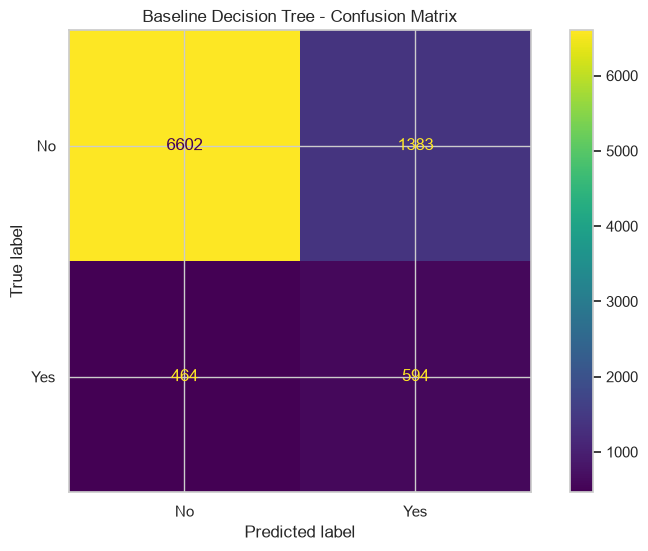

In [125]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

# Predictions
y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)[:, 1]

# Evaluation
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Subscription", "Subscription"],
        zero_division=0
    )
)

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No", "Yes"]
)

plt.title("Baseline Decision Tree - Confusion Matrix")
plt.show()

In [126]:
from sklearn.metrics import accuracy_score, f1_score

# Training predictions
y_train_pred = baseline_model.predict(X_train)

# Test predictions
y_test_pred = baseline_model.predict(X_test)

# Compare performance
print("Training Accuracy:",
      round(accuracy_score(y_train, y_train_pred), 4))

print("Testing Accuracy:",
      round(accuracy_score(y_test, y_test_pred), 4))

print("\nTraining F1-score:",
      round(f1_score(y_train, y_train_pred), 4))

print("Testing F1-score:",
      round(f1_score(y_test, y_test_pred), 4))

Training Accuracy: 0.7994
Testing Accuracy: 0.7958

Training F1-score: 0.391
Testing F1-score: 0.3914


In [128]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

depth_results = []

for depth in [3, 5, 7, 10, 15, None]:

    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                DecisionTreeClassifier(
                    criterion="gini",
                    max_depth=depth,
                    min_samples_leaf=20,
                    class_weight="balanced",
                    random_state=42
                )
            )
        ]
    )

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "f1": "f1",
            "precision": "precision",
            "recall": "recall",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    depth_results.append({
        "max_depth": str(depth),
        "F1_mean": scores["test_f1"].mean(),
        "F1_std": scores["test_f1"].std(),
        "Precision_mean": scores["test_precision"].mean(),
        "Recall_mean": scores["test_recall"].mean(),
        "ROC_AUC_mean": scores["test_roc_auc"].mean()
    })

depth_results_df = pd.DataFrame(depth_results)

depth_results_df.sort_values(
    by="F1_mean",
    ascending=False
).round(4)

,max_depth,F1_mean,F1_std,Precision_mean,Recall_mean,ROC_AUC_mean
2,7,0.4237,0.0201,0.3447,0.5550,0.7555
3,10,0.4142,0.0160,0.3200,0.5899,0.7686
1,5,0.3795,0.0118,0.2921,0.5434,0.7357
4,15,0.3643,0.0098,0.2570,0.6278,0.7557
5,None,0.3460,0.0088,0.2369,0.6417,0.7396
0,3,0.3111,0.0049,0.2044,0.6509,0.7074


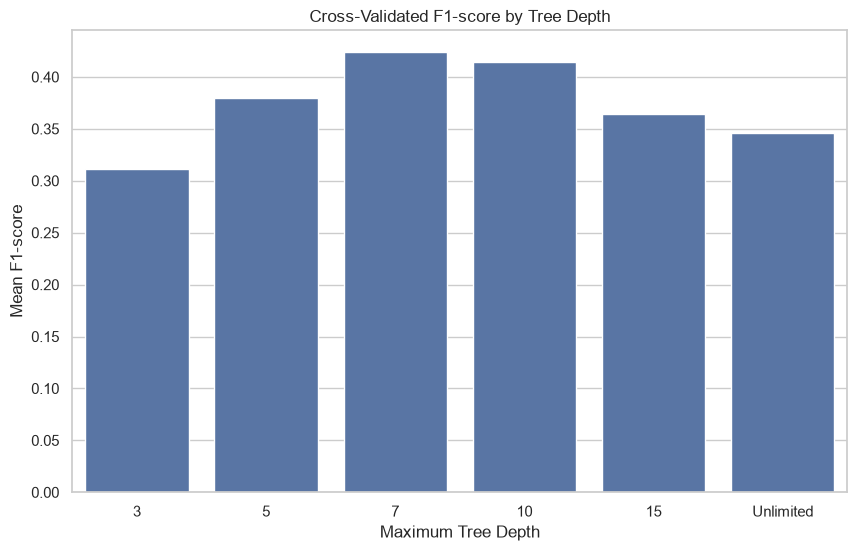

In [129]:
plot_df = depth_results_df.copy()

plot_df["max_depth"] = plot_df["max_depth"].replace(
    "None",
    "Unlimited"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_df,
    x="max_depth",
    y="F1_mean"
)

plt.title("Cross-Validated F1-score by Tree Depth")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Mean F1-score")

plt.show()

In [130]:
criterion_results = []

for criterion in ["gini", "entropy", "log_loss"]:

    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                DecisionTreeClassifier(
                    criterion=criterion,
                    max_depth=5,
                    min_samples_leaf=20,
                    class_weight="balanced",
                    random_state=42
                )
            )
        ]
    )

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    criterion_results.append({
        "criterion": criterion,
        "F1_mean": scores["test_f1"].mean(),
        "ROC_AUC_mean": scores["test_roc_auc"].mean()
    })

criterion_results_df = pd.DataFrame(criterion_results)

criterion_results_df.sort_values(
    by="F1_mean",
    ascending=False
).round(4)

,criterion,F1_mean,ROC_AUC_mean
1,entropy,0.3802,0.7357
2,log_loss,0.3802,0.7357
0,gini,0.3795,0.7357


In [131]:
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

param_grid = {
    "classifier__criterion": [
        "gini",
        "entropy",
        "log_loss"
    ],
    "classifier__max_depth": [
        3, 5, 7, 10, None
    ],
    "classifier__min_samples_split": [
        2, 10, 20
    ],
    "classifier__min_samples_leaf": [
        10, 20, 50
    ]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validated F1-score:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 135 candidates, totalling 675 fits
Best parameters:
{'classifier__criterion': 'entropy', 'classifier__max_depth': 7, 'classifier__min_samples_leaf': 20, 'classifier__min_samples_split': 2}

Best cross-validated F1-score:
0.4336


Tuned Model — Test Results

                 precision    recall  f1-score   support

No Subscription       0.94      0.86      0.90      7985
   Subscription       0.35      0.57      0.43      1058

       accuracy                           0.83      9043
      macro avg       0.64      0.72      0.67      9043
   weighted avg       0.87      0.83      0.84      9043

Test ROC-AUC: 0.7645


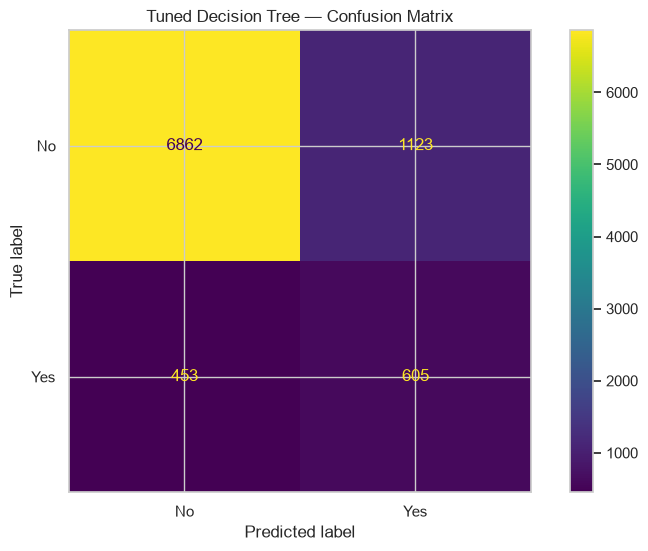

In [132]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score
)

best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

print("Tuned Model — Test Results\n")

print(
    classification_report(
        y_test,
        y_pred_tuned,
        target_names=["No Subscription", "Subscription"],
        zero_division=0
    )
)

print(
    "Test ROC-AUC:",
    round(roc_auc_score(y_test, y_prob_tuned), 4)
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    display_labels=["No", "Yes"]
)

plt.title("Tuned Decision Tree — Confusion Matrix")
plt.show()

In [133]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Retrieve the trained Decision Tree
tree_model = best_model.named_steps["classifier"]

# Retrieve feature names after preprocessing
feature_names = (
    best_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

print("Number of features:", len(feature_names))

Number of features: 51


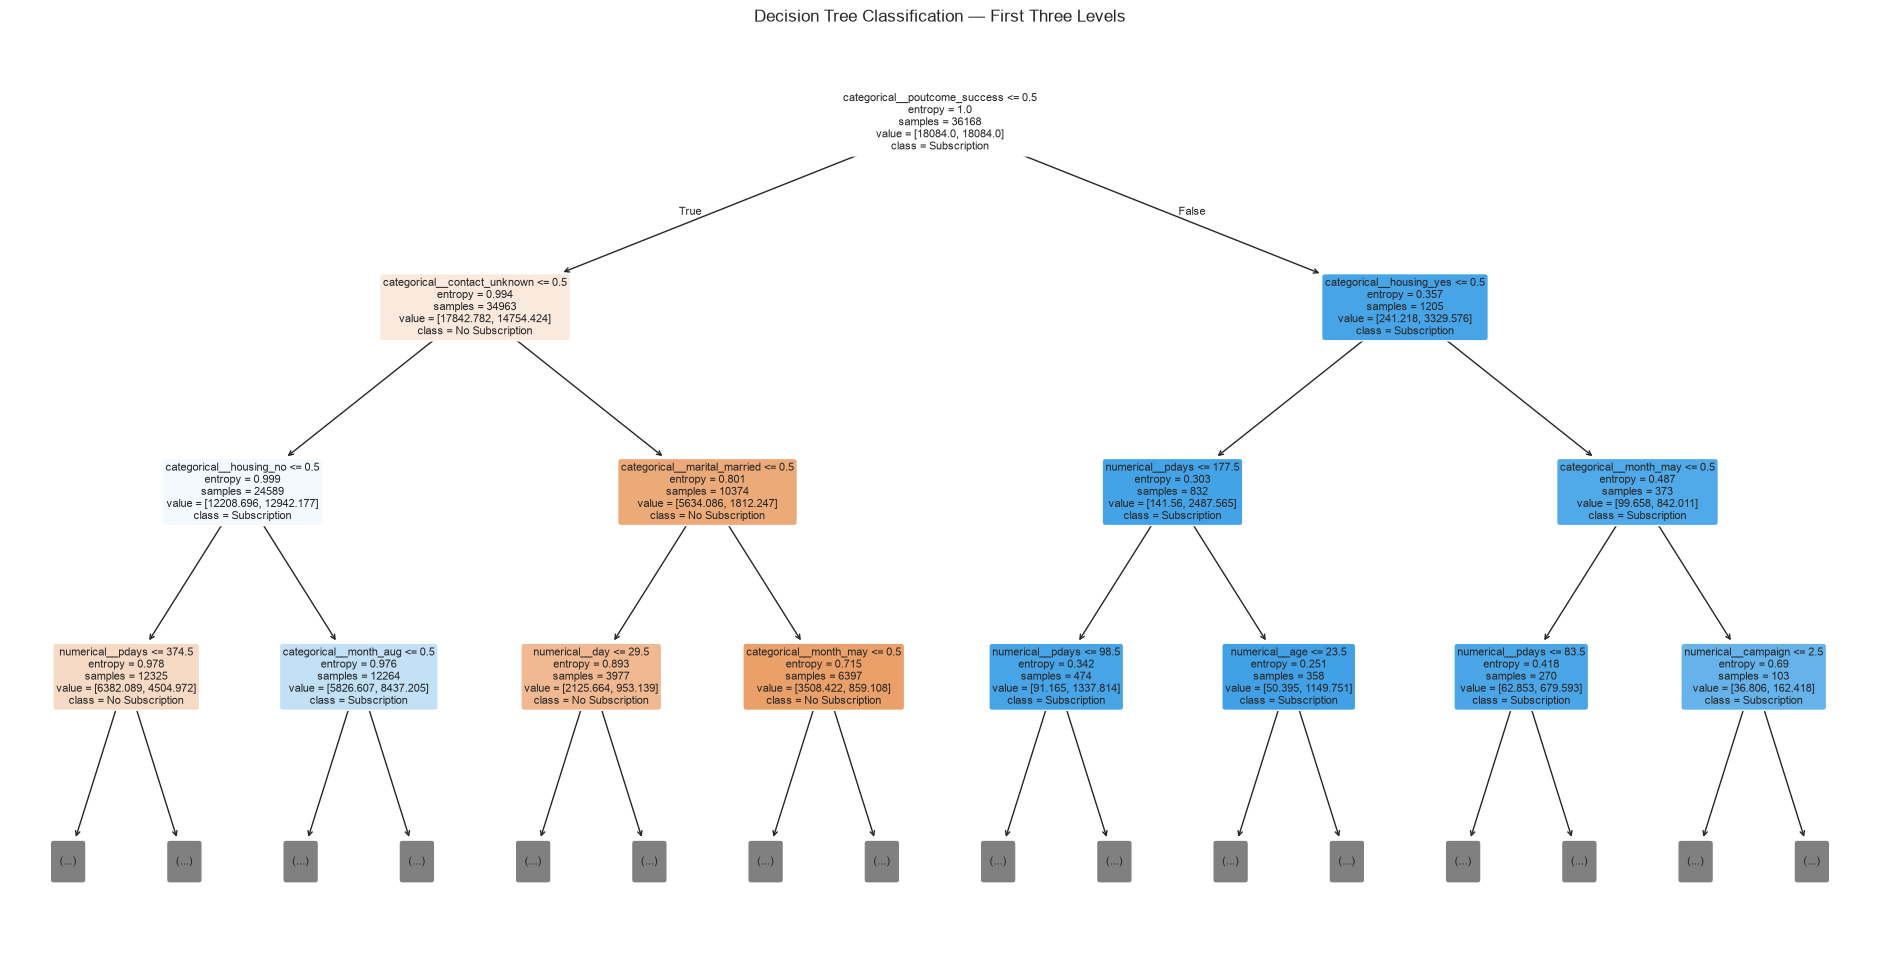

In [136]:
plt.figure(figsize=(24, 12))

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=["No Subscription", "Subscription"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Classification — First Three Levels")
plt.show()

In [142]:
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tree_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(5)

,Feature,Importance
42,categorical__poutcome_success,0.341098
27,categorical__contact_unknown,0.175255
21,categorical__housing_no,0.076941
48,numerical__pdays,0.055396
46,numerical__day,0.052941


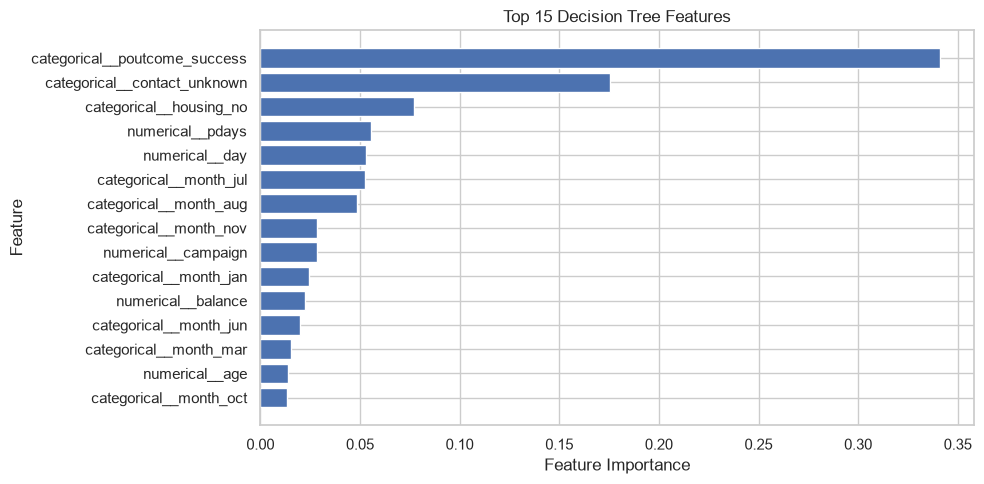

In [143]:
top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 5))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Decision Tree Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [144]:
error_analysis = X_test.copy()

error_analysis["Actual"] = y_test
error_analysis["Predicted"] = best_model.predict(X_test)

error_analysis["Prediction_Result"] = "Correct"

error_analysis.loc[
    (error_analysis["Actual"] == 1) &
    (error_analysis["Predicted"] == 0),
    "Prediction_Result"
] = "False Negative"

error_analysis.loc[
    (error_analysis["Actual"] == 0) &
    (error_analysis["Predicted"] == 1),
    "Prediction_Result"
] = "False Positive"

error_analysis["Prediction_Result"].value_counts()

Prediction_Result
Correct           7467
False Positive    1123
False Negative     453
Name: count, dtype: int64

In [146]:
from pathlib import Path
import joblib

ROOT_DIR = Path.cwd().parent

MODEL_DIR = ROOT_DIR / "model"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "decision_tree_final.joblib"

joblib.dump(best_model, MODEL_PATH)

print(f"Model saved to: {MODEL_PATH}")

Model saved to: /Users/alfaizkhan/Documents/Machine learning/Supervised learning/Classification/decision-tree-bank-marketing/model/decision_tree_final.joblib


In [147]:
print("Best hyperparameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(grid_search.best_score_, 4))

Best hyperparameters:
{'classifier__criterion': 'entropy', 'classifier__max_depth': 7, 'classifier__min_samples_leaf': 20, 'classifier__min_samples_split': 2}

Best cross-validation F1-score:
0.4336


In [148]:
print("Final test classification report:")
print(
    classification_report(
        y_test,
        grid_search.best_estimator_.predict(X_test),
        target_names=["No Subscription", "Subscription"],
        zero_division=0
    )
)

Final test classification report:
                 precision    recall  f1-score   support

No Subscription       0.94      0.86      0.90      7985
   Subscription       0.35      0.57      0.43      1058

       accuracy                           0.83      9043
      macro avg       0.64      0.72      0.67      9043
   weighted avg       0.87      0.83      0.84      9043



In [149]:
from pathlib import Path

ROOT_DIR = Path.cwd().parent
FIGURES_DIR = ROOT_DIR / "reports" / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Figures directory:", FIGURES_DIR)

Figures directory: /Users/alfaizkhan/Documents/Machine learning/Supervised learning/Classification/decision-tree-bank-marketing/reports/figures
